In [25]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv('ride_hailing_dataset.csv')

print(df.head())
print(df.info())

  trip_id       city service_type    fare  distance_km payment_method  \
0    T001     Lahore         Uber  984.44         17.2           Cash   
1    T002  Islamabad         Uber  539.46          2.5         Wallet   
2    T003    Karachi       Careem  401.60          8.0           Card   
3    T004     Lahore         Uber  932.56         16.2         Wallet   
4    T005     Lahore     Rickshaw  148.61         19.2           Card   

   trip_rating  gender  
0            3  Female  
1            5  Female  
2            4    Male  
3            3  Female  
4            5  Female  
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   trip_id         100 non-null    str    
 1   city            100 non-null    str    
 2   service_type    100 non-null    str    
 3   fare            100 non-null    float64
 4   distance_km     100 non-null    float64
 5  

In [26]:
fare_by_service = (
    df.groupby('service_type')['fare']
    .agg(['count', 'mean', 'median', 'min', 'max', 'std'])
    .sort_values(by='mean', ascending=False)
)
print(fare_by_service)

              count        mean   median     min     max         std
service_type                                                        
InDrive          23  573.514783  621.120  107.35  952.15  264.279316
Careem           30  544.975000  474.660  123.61  991.49  274.970146
Rickshaw         25  486.637200  496.470  134.33  942.48  272.366248
Uber             22  486.125455  508.905  125.10  984.44  239.126700


In [27]:
print(df['city'].value_counts())

city
Islamabad     29
Lahore        26
Karachi       23
Rawalpindi    22
Name: count, dtype: int64


In [28]:
avg_distance = df['distance_km'].mean()
print(f'Average distance per trip: {avg_distance:.2f} km')
print(df['distance_km'].describe())

Average distance per trip: 9.61 km
count    100.000000
mean       9.613000
std        5.212585
min        1.200000
25%        5.075000
50%        9.700000
75%       13.050000
max       19.500000
Name: distance_km, dtype: float64


In [29]:
ratings_by_gender = df.groupby('gender')['trip_rating'].agg(
    ['count', 'mean', 'median', 'min', 'max', 'std']
)
print(ratings_by_gender)

        count      mean  median  min  max       std
gender                                             
Female     51  2.823529     3.0    1    5  1.465686
Male       49  3.326531     4.0    1    5  1.463269


C:\Users\shahe\AppData\Local\Temp\ipykernel_12280\1477105597.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


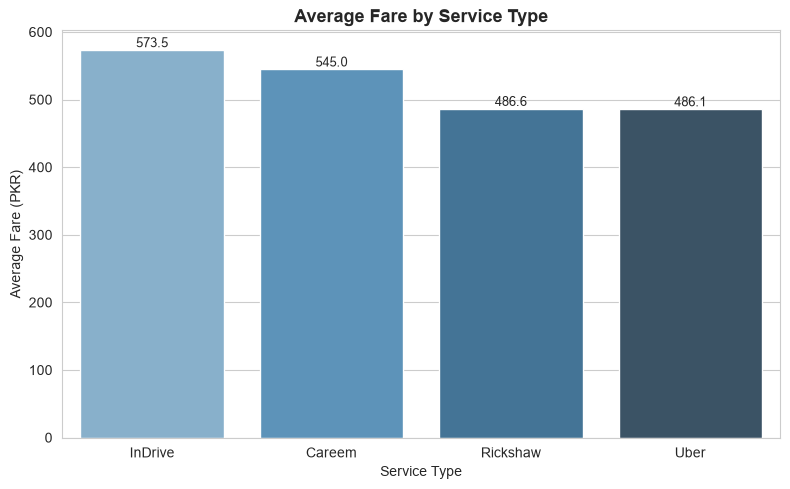

In [30]:
svc_order = (
    df.groupby('service_type')['fare'].mean().sort_values(ascending=False).index
)

plt.figure(figsize=(8, 5))
sns.set_style('whitegrid')
ax = sns.barplot(
    data=df,
    x='service_type',
    y='fare',
    order=svc_order,
    errorbar=None,
    palette='Blues_d',
)
plt.title('Average Fare by Service Type', fontsize=13, fontweight='bold')
plt.xlabel('Service Type')
plt.ylabel('Average Fare (PKR)')

for p in ax.patches:
  ax.annotate(
      f'{p.get_height():.1f}',
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha='center',
      va='bottom',
      fontsize=9,
  )

plt.tight_layout()
plt.show()